# Projet Black-Scholes : mise en pratique d'un cours d'évaluation des options

*Projet personnel en cours, réalisé pour approfondir le cours* Introduction à l'évaluation des produits financiers *(M1 Actuariat, ISUP, 2026-2027). Le contexte, les hypothèses et les limites sont détaillés dans le fichier `README.md`.*

## Contexte

Le cours montre comment donner un prix à une option sous l'hypothèse d'AOA : d'abord dans le modèle binomial, puis dans le modèle log-normal, qui mène à la formule de Black-Scholes.

Ce notebook met en œuvre ces résultats en Python, puis les applique à un exemple simple d'assurance vie : une personne place son épargne sur les marchés, et l'assureur garantit qu'en cas de décès ses proches recevront au moins le montant placé au départ. Cette garantie revient à un ensemble d'options de vente (Puts).

## Organisation

1. **Étape 1 — La formule de Black-Scholes** : prix du Call et du Put dans le modèle log-normal, vérifiés avec des propriétés vues en cours (parité Call-Put, bornes et variations en fonction du strike).
2. **Étape 2 — Le modèle binomial** : prix d'une option dans un arbre à n périodes, et convergence vers le prix de Black-Scholes quand n augmente.
3. **Étape 3 — La garantie en cas de décès** : coût de la garantie pour un assuré de 60 ans sur 10 ans, à partir des prix de Puts et d'une table de mortalité, puis sensibilité à la volatilité, à l'âge et au taux.

# Étape 1 — La formule de Black-Scholes
**But :** coder les prix du Call et du Put européens dans le modèle log-normal.

In [14]:
import numpy as np
from scipy.stats import norm, binom
import matplotlib.pyplot as plt
import pandas as pd
import os
os.makedirs("figures", exist_ok=True)   # crée le dossier figures s'il n'existe pas

## 1. Les quantités d₊ et d₋

In [15]:
def d_plus_moins(S0, K, T, r, sigma):
    d_plus = 1/(sigma*np.sqrt(T))*np.log(S0*np.exp(r*T)/K) + 1/2*sigma*np.sqrt(T)
    d_moins = d_plus - sigma * np.sqrt(T)
    return d_plus, d_moins

## 2. Prix du Call et du Put 

In [16]:
def bs_call(S0, K, T, r, sigma):
    (d1,d2)= d_plus_moins(S0, K, T, r, sigma)
    return S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    
def bs_put(S0, K, T, r, sigma):
    (d1,d2)= d_plus_moins(S0, K, T, r, sigma)
    return K*np.exp(-r*T)*norm.cdf(-d2) - S0*norm.cdf(-d1)

## 4. Tests

In [17]:
S0, K, T, r, sigma = 100, 100, 1, 0.05, 0.20
B = np.exp(-r * T)

C = bs_call(S0, K, T, r, sigma)
P = bs_put(S0, K, T, r, sigma)

# Test 2 — parité Call-Put sans dividende
assert abs((C - P) - (S0 - K * B)) < 1e-10

strikes = np.array([80, 90, 100, 110, 120])
calls = np.array([bs_call(S0, k, T, r, sigma) for k in strikes])
puts = np.array([bs_put(S0, k, T, r, sigma) for k in strikes])

# Test 3 — relations de couverture 
assert np.all(np.maximum(S0 - strikes * B, 0) <= calls) and np.all(calls <= S0)
assert np.all(np.maximum(strikes * B - S0, 0) <= puts) and np.all(puts <= strikes * B)

# Test 4 — Bull Spread
assert np.all(np.diff(calls) < 0)
assert np.all(np.diff(puts) > 0)

# Test 5 — Butterfly Spread
assert np.all(calls[:-2] - 2 * calls[1:-1] + calls[2:] >= 0)
assert np.all(puts[:-2] - 2 * puts[1:-1] + puts[2:] >= 0)

# Étape 2 — L'arbre binomial et sa convergence vers Black-Scholes

**But :** calculer le prix d'une option dans le modèle binomial à n périodes (corollaire 5.8), puis montrer que ce prix converge vers la formule de Black-Scholes quand n augmente (théorème 6.5)

## Partie A — Le modèle binomial à n périodes

In [18]:
def payoff_call(ST, K):
    return np.maximum(ST - K, 0)

def payoff_put(ST, K):
    return np.maximum(K - ST, 0)
    
def prix_binomial(S0, u, d, r, n, payoff):
    assert u > 1 + r > d > 0
    p_tilde = (1 + r -d)/(u-d)
    k = np.arange(n+1)
    ST = S0*(u**k)*(d**(n-k))                 
    poids = binom.pmf(k, n, p_tilde)                  
    return (1+r)**(-n)*np.sum(poids*payoff(ST))

## Partie B — Convergence vers Black-Scholes

In [19]:
def binomial_call(S0, K, T, r, sigma, n):
    u_n = np.exp(sigma*np.sqrt(T/n))
    d_n = np.exp(-sigma*np.sqrt(T/n))
    r_n = r*T/n
    return prix_binomial(S0, u_n, d_n, r_n, n, lambda ST: payoff_call(ST, K))
    
def binomial_put(S0, K, T, r, sigma, n):
    u_n = np.exp(sigma*np.sqrt(T/n))
    d_n = np.exp(-sigma*np.sqrt(T/n))
    r_n = r*T/n
    return prix_binomial(S0, u_n, d_n, r_n, n, lambda ST: payoff_put(ST, K))

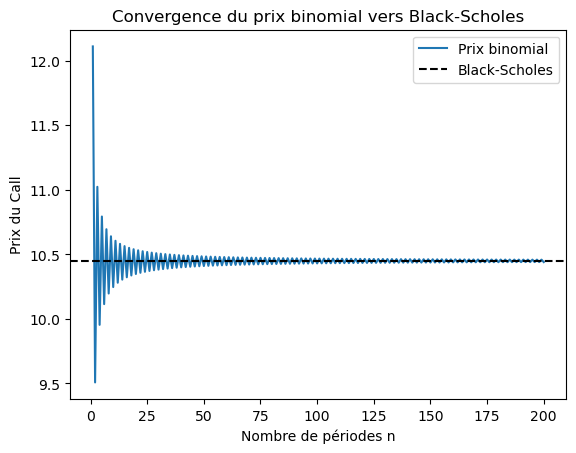

In [20]:
S0, K, T, r, sigma = 100, 100, 1, 0.05, 0.20
ns = np.arange(1, 201)
prix_n = [binomial_call(S0, K, T, r, sigma, n) for n in ns]

plt.plot(ns, prix_n, label="Prix binomial")
plt.axhline(bs_call(S0, K, T, r, sigma), color="black", linestyle="--", label="Black-Scholes")
plt.xlabel("Nombre de périodes n")
plt.ylabel("Prix du Call")
plt.title("Convergence du prix binomial vers Black-Scholes")
plt.legend()
plt.savefig("figures/convergence_binomial.png", dpi=150, bbox_inches="tight")
plt.show()

# Étape 3 — Valoriser une garantie plancher décès

**Le contrat.** Un assuré de 60 ans verse 10 000 € sur un contrat en unités de compte. La valeur du contrat suit le modèle log-normal du polycopié (S₀ = 10 000 €, volatilité σ). S'il décède dans les 10 ans, l'assureur garantit aux bénéficiaires au moins K = 10 000 €.

**Le payoff.** Si le décès a lieu à la fin de l'année t, l'assureur verse (K − S_t)⁺ : c'est le payoff d'un **Put** de maturité t.

**La valeur de la garantie.** On suppose la mortalité indépendante des marchés. Par linéarité du prix :

Valeur = Σ_{t=1}^{10} P(décès pendant l'année t) × Put₀(t, K)

où Put₀(t, K) est donné par le théorème 6.6.

In [21]:
table = pd.read_csv("table_mortalite.csv")
lx = table.set_index("age")["lx"]  
print(table.head())

   age      lx
0    0  100000
1    1   99511
2    2   99473
3    3   99446
4    4   99424


## Partie A — Les probabilités de décès

In [22]:
def probas_deces(lx, x, horizon):
    probas = []
    for t in range(1, horizon + 1):
        p_t = (lx[x+t-1]-lx[x+t])/lx[x]
        probas.append(p_t)
    return np.array(probas)

x, horizon = 60, 10
P_deces = probas_deces(lx, x, horizon)
for t, p in enumerate(P_deces, start=1):
    print(f"Année {t:2d} : {p:.4%}")
print(f"Probabilité de décéder dans les {horizon} ans : {P_deces.sum():.2%}")

Année  1 : 1.1457%
Année  2 : 1.2205%
Année  3 : 1.3035%
Année  4 : 1.3947%
Année  5 : 1.4964%
Année  6 : 1.6063%
Année  7 : 1.7232%
Année  8 : 1.8436%
Année  9 : 1.9699%
Année 10 : 2.1008%
Probabilité de décéder dans les 10 ans : 15.80%


## Partie B — La valeur de la garantie

In [23]:
def valeur_garantie(lx, x, horizon, S0, K, r, sigma):
    S = 0
    probas = probas_deces(lx, x, horizon)
    for t in range(1, horizon+1):
        S+=probas[t-1]*bs_put(S0, K, t, r, sigma)
    return S

S0 = K = 10_000
r, sigma = 0.03, 0.20
V = valeur_garantie(lx, x, horizon, S0, K, r, sigma)
print(f"Valeur de la garantie : {V:.2f} €, soit {V / S0:.3%} du versement")

Valeur de la garantie : 159.57 €, soit 1.596% du versement


## Sensibilités

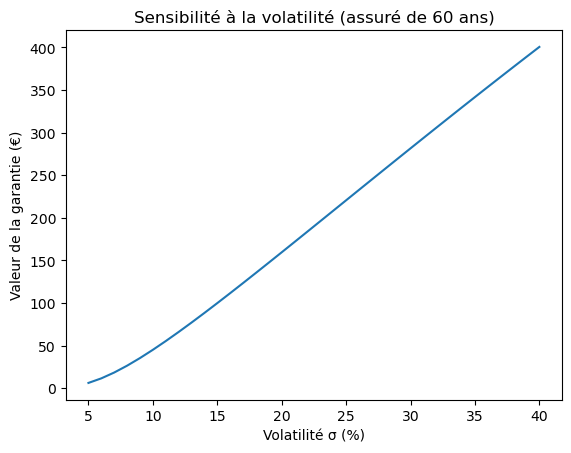

In [24]:
sigmas = np.linspace(0.05, 0.40, 36)
plt.plot(sigmas * 100, [valeur_garantie(lx, x, horizon, S0, K, r, s) for s in sigmas])
plt.xlabel("Volatilité σ (%)")
plt.ylabel("Valeur de la garantie (€)")
plt.title("Sensibilité à la volatilité (assuré de 60 ans)")
plt.savefig("figures/sensibilite_sigma.png", dpi=150, bbox_inches="tight")
plt.show()

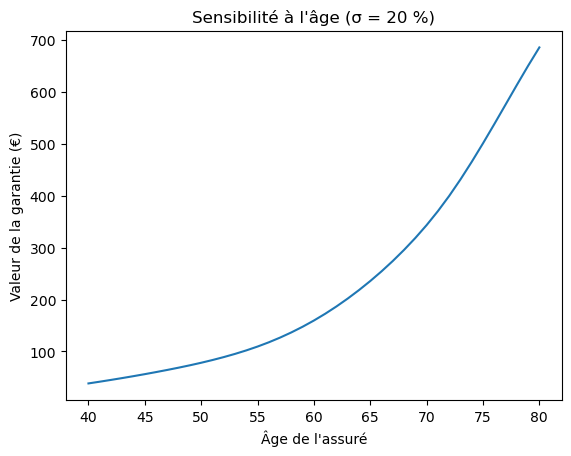

In [25]:
ages = np.arange(40, 81)
plt.plot(ages, [valeur_garantie(lx, a, horizon, S0, K, r, sigma) for a in ages])
plt.xlabel("Âge de l'assuré")
plt.ylabel("Valeur de la garantie (€)")
plt.title("Sensibilité à l'âge (σ = 20 %)")
plt.savefig("figures/sensibilite_age.png", dpi=150, bbox_inches="tight")
plt.show()

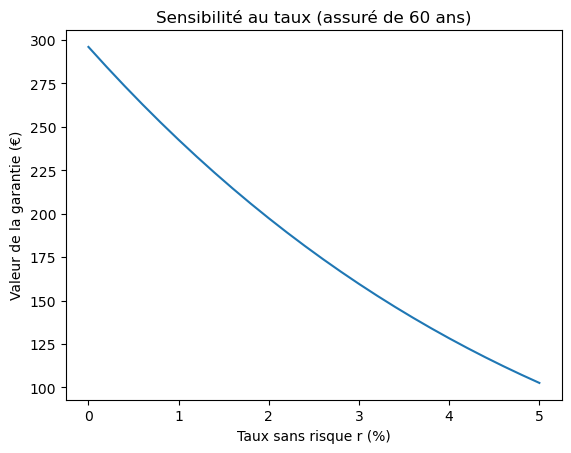

In [26]:
taux = np.linspace(0.0, 0.05, 26)
plt.plot(taux * 100, [valeur_garantie(lx, x, horizon, S0, K, rr, sigma) for rr in taux])
plt.xlabel("Taux sans risque r (%)")
plt.ylabel("Valeur de la garantie (€)")
plt.title("Sensibilité au taux (assuré de 60 ans)")
plt.savefig("figures/sensibilite_taux.png", dpi=150, bbox_inches="tight")
plt.show()